# Q2B | Display the Statistical Values

> *Display the statistical values for each of the attributes, along with visualizations (ex: histogram) of the distributions for each attribute. Explain noticeable traits for key attributes. Are there any attributes that might require special treatment? If so, what special treatment might they require?*

---

#### IMPORTANT

This dataset has no `train` / `test` split of its own, so the split is made at the top of this notebook. It is chronological: the earliest 584 days are `train` and the latest 147 days are `test`. Every statistic below is computed on the training rows only, so no analysis or treatment decision is influenced by the test data (`data snooping`).

# Answer Summary

**Statistics and visualizations**
- **Continuous attributes** (`Temp`, `FeelsLike`, `Humidity`, `Wind`): a statistics table (center, spread, skew, kurtosis, IQR outliers, correlation with `Rentals`) and four plots (histogram w/ normal overlay, QQ plot, Rentals box plot split at a threshold, and a scatter against Rentals with linear, LOWESS, step and hinge fits).
- **Categorical attributes** (`Season`, `Year`, `Month`, `IsHoliday`, `Weekday`, `IsWorkday`, `Weather`): a table of Rentals statistics per level and two plots (rows per level, and a Rentals box plot per level with the level means R²).
- **Target** (`Rentals`): the same statistics table as a continuous attribute (without the correlation), with the histogram and QQ plot only.

**Noticeable traits**
- **The target, Rentals, is roughly symmetric** (skew 0.067) with no outliers, but its histogram has more than one peak.
- **Strongest relationships with Rentals:** FeelsLike (r = 0.69, R² = 0.48), Temp (r = 0.685, R² = 0.47), Month (level means R² = 0.45), Season (0.37) and Year (0.29).
- **Weakest:** IsHoliday, Weekday and IsWorkday (level means R² = 0.00 each), Humidity (r = -0.128, R² = 0.02) and Wind (r = -0.196, R² = 0.04).
- **Temp and FeelsLike rise, then flatten.** LOWESS climbs steeply up to about 0.6 and is nearly flat above it. A hinge lifts R² from 0.47 to 0.52 (Temp) and from 0.48 to 0.53 (FeelsLike).
- **The four continuous attributes are close to symmetric.** Only Wind is skewed (0.668, moderate), with 12 high outliers. Humidity has a single low outlier, a value of exactly 0.0.
- **The category codes are labels, not quantities.** The Rentals means do not follow the code order for Season (2,651 / 4,992 / 5,179 / 3,664) or Month (rising to month 6, then falling).
- **Some levels have few rows:** IsHoliday level 1 (16 rows) and Weather level 3 (18 rows).
- **The chronological split leaves the calendar uneven in train.** Train ends on 2012-08-06, so months 9 to 12 only have rows from the first year (30 or 31 rows each, vs 57 to 62 for months 1 to 7), and Year level 1 only covers part of a year (219 rows vs 365).

**Attributes that might require special treatment**

| Attribute | What the data shows | Candidate treatment |
|---|---|---|
| Temp | Rises then flattens (hinge slopes 9360.95 / -358.32 at 0.58) | Hinge/spline near 0.58, or a squared term |
| FeelsLike | Same shape as Temp (hinge slopes 9665.32 / -3086.80 at 0.60) | Same as Temp |
| Humidity | Weak; falls only above about 0.70 (hinge slopes 1641.73 / -9191.70); one value of exactly 0.0 | Hinge near 0.70 or an indicator for high values; check the 0.0 row |
| Wind | Moderately right skewed (0.668); 12 high outliers; weak | A transform that pulls in the high tail (ex log, square root), or none |
| Season | 4 codes; Rentals means not in code order | One-hot encode |
| Month | 12 codes; Rentals means rise then fall; months 9 to 12 only have first year rows | One-hot encode, or a cyclical (sine / cosine) encoding |
| Weather | 3 codes; Rentals means fall as the code rises, in unequal steps; level 3 has 18 rows | One-hot encode |
| Weekday | 7 codes; no difference between levels (R² = 0.00) | One-hot encode if kept; candidate to drop |
| Year | Already 0 / 1; level 1 mean is higher (5,400 vs 3,406) | None |
| IsHoliday | Already 0 / 1; 16 rows at level 1; R² = 0.00 | None; candidate to drop |
| IsWorkday | Already 0 / 1; R² = 0.00 | None; candidate to drop |
| Casual, Registered | Add up to Rentals in every train row | Do not use as attributes (they give the target away) |
| ID, Date | One distinct value per row | Do not use as they are |
| Rentals (target) | Roughly symmetric (skew 0.067); no outliers; more than one peak | None |

These are candidates only. They are tested in the next notebook. Missing values are covered in Q2A.

---

# Imports

In [1]:
import pandas as pd
from IPython.display import display

from OLD.Q2.consts import *

from OLD.Q2.utils import (
	read_csv_to_df,
	PLOTTING,
	STATISTICS
)

from OLD.Q2.utils import (
	chronological_split,
	Q2_PLOTTING,
	Q2_STATISTICS
)

# Defaults

In [2]:
pd.set_option('display.max_rows', None)
pd.set_option('display.min_rows', None)
pd.set_option('display.max_columns', None)

# Fetch Data

In [3]:
df = read_csv_to_df(path=DATA_PATH, parse_dates=["dteday"])
df = df.rename(columns=SHORT_NAMES)

# Train / Test Split

In [4]:
train_df, test_df = chronological_split(df=df, date_col="Date", test_size=TEST_SIZE)

pd.DataFrame({
	"rows": [len(train_df), len(test_df)],
	"% of rows": [round(len(train_df) / len(df) * 100, 2), round(len(test_df) / len(df) * 100, 2)],
	"first date": [f"{train_df['Date'].min():%Y-%m-%d}", f"{test_df['Date'].min():%Y-%m-%d}"],
	"last date": [f"{train_df['Date'].max():%Y-%m-%d}", f"{test_df['Date'].max():%Y-%m-%d}"],
}, index=["train", "test"])

,rows,% of rows,first date,last date
train,584,79.89,2011-01-01,2012-08-06
test,147,20.11,2012-08-07,2012-12-31


- **The split is chronological.** The rows are ordered by `Date` and cut once, with no shuffling: the earliest 584 rows (79.89%) are train and the latest 147 rows (20.11%) are test.
- **Train** covers 2011-01-01 to 2012-08-06. **Test** covers 2012-08-07 to 2012-12-31.
- Train therefore holds the whole first year and the second year only up to 2012-08-06. This shows up in the `Year` and `Month` row counts below.
- `test_df` is not used again in this notebook.
- `TEST_SIZE` is set in `Q2/consts.py` and the split is made by `chronological_split` in `Q2/utils`, so later notebooks can make the same split.

# Statistical Values: Continuous Attributes

## How to Read the Plots (applies to every continuous attribute below)

- **Histogram w/ normal overlay:** the attribute's distribution against a normal curve with the same mean and SD. Gaps between the bars and the red curve show skew, values piling up at one end, or more than one peak.
- **QQ plot:** the sorted values against the values a normal distribution would produce. Points on the red line mean normal.
  - Low end below the line and high end above it: heavy tails. The reverse: light tails.
  - Points bowing above the line through the middle: left skew. Bowing below: right skew.
  - A flat run at one end: values piling up against a limit.
- **Box plot:** Rentals for the rows below vs at or above the step threshold. The further apart the boxes, the more a simple above/below split explains.
- **Scatter plot fits:**
  - **Linear (red):** the straight line. This is the only shape a raw attribute can give a linear regression.
  - **LOWESS (green):** a smoothed local average that does not assume a shape. When it bends away from the red line, the relationship is not linear and the raw attribute will underfit.
  - **Step (blue, dotted):** one mean on each side of a threshold. If its R² is close to the linear R², an above/below indicator carries most of the signal.
  - **Hinge (violet, dashed):** two straight segments joined at a threshold. If its R² beats the linear R², the attribute is a candidate for a hinge or spline term.
  - The step and hinge thresholds are searched on the same rows they are scored on, so their R² values are optimistic.

## Rentals (Target)

In [5]:
display(STATISTICS.statistics_df(series=train_df[TARGET]))

,Rentals
count,584.0
missing,0
% missing,0.0
mean,4153.599
std,1788.888
min,431.0
25%,2806.5
50%,4200.0
75%,5219.0
max,8362.0


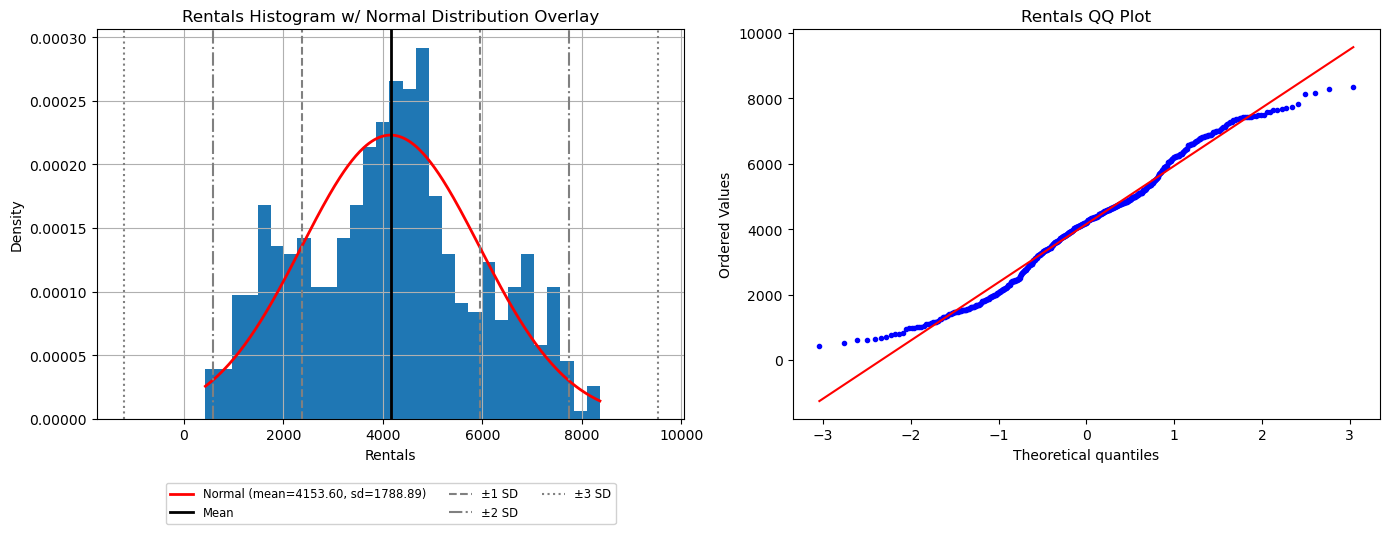

In [6]:
PLOTTING.distribution_plots(series=train_df[TARGET]);

### Notes / Observations

The target has no box plot or scatter plot, since those show an attribute against the target. Its table has no `corr with target` row for the same reason.

#### Noticeable Traits / Key Attributes

- **Roughly symmetric (0.067), mesokurtic (-0.675).** The mean (4153.599) and median (4200.0) are close, and half the values sit between 2806.5 and 5219.0.
- **Wide range:** 431 to 8,362 rentals in a day, with a standard deviation of 1788.888.
- **Histogram:** more than one peak. The main peak is around 4,000 to 5,000, with a lower hump around 1,500 to 2,000 and a shoulder near 7,000.
- **QQ plot:** the points weave around the line instead of sitting on it, which matches the several peaks. The low end sits above the line and the high end below it (light tails).
- **No outliers** on either side (fences -812.25 and 8837.75), and no missing values.
- More than one peak suggests the rows come from groups with different Rentals levels. The categorical sections below show such groups (ex `Year`: mean 3,406 at level 0 vs 5,400 at level 1).

#### Special Treatment

- **None needed.** There is no skew to fix and no outlier to handle, so the target is left as it is.

## Temp

In [7]:
display(STATISTICS.statistics_df(series=train_df['Temp'], target=train_df[TARGET]))

,Temp
count,584.0
missing,0
% missing,0.0
mean,0.497
std,0.188
min,0.059
25%,0.336
50%,0.502
75%,0.66
max,0.862


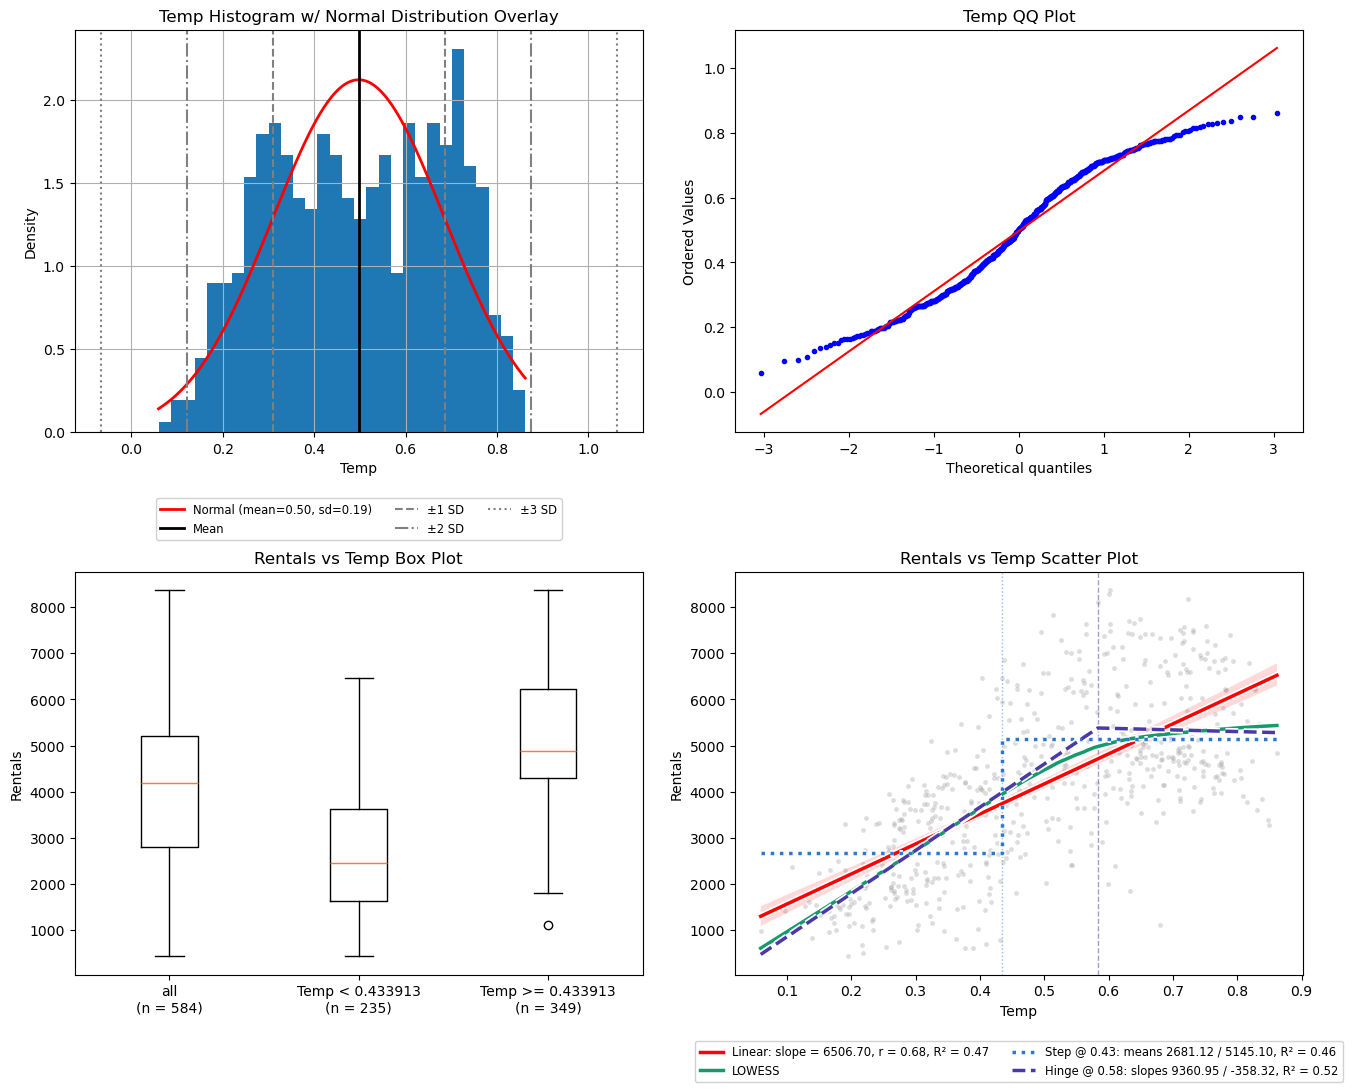

In [8]:
PLOTTING.single_feature_plots(df=train_df, feature='Temp', target=TARGET, threshold="auto");

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **Roughly symmetric (-0.083) and platykurtic (excess kurtosis -1.11).** The histogram is broad and flat topped, with two humps (around 0.3 and around 0.7) and no single peak at the mean of 0.497.
- **QQ plot:** the low end sits above the line and the high end below it (light tails), since the values stay inside a compact range (0.059 to 0.862).
- **No outliers** on either side.
- **Strong positive relationship with Rentals:** r = 0.685 (R² 0.47).
- **Rises, then flattens.** LOWESS climbs steeply up to about 0.6 and is nearly flat above it. The hinge at 0.58 changes the slope from 9360.95 to -358.32 and lifts R² from 0.47 to 0.52. The straight line keeps rising where LOWESS is flat, so it sits above LOWESS at both ends of the range.
- The step at 0.43 alone gives means of 2681.12 / 5145.10 (R² 0.46, almost the linear R²). The box plot shows the same split: the 235 rows below 0.433913 have a median Rentals of about 2,450, vs about 4,900 for the 349 rows at or above it.

#### Special Treatment

- **A hinge or spline term** near 0.58, which matches the rise then flatten shape directly.
- **Or a squared term,** which also lets the line bend.
- **No outlier or skew treatment needed.**

## FeelsLike

In [9]:
display(STATISTICS.statistics_df(series=train_df['FeelsLike'], target=train_df[TARGET]))

,FeelsLike
count,584.0
missing,0
% missing,0.0
mean,0.476
std,0.168
min,0.079
25%,0.336
50%,0.49
75%,0.615
max,0.841


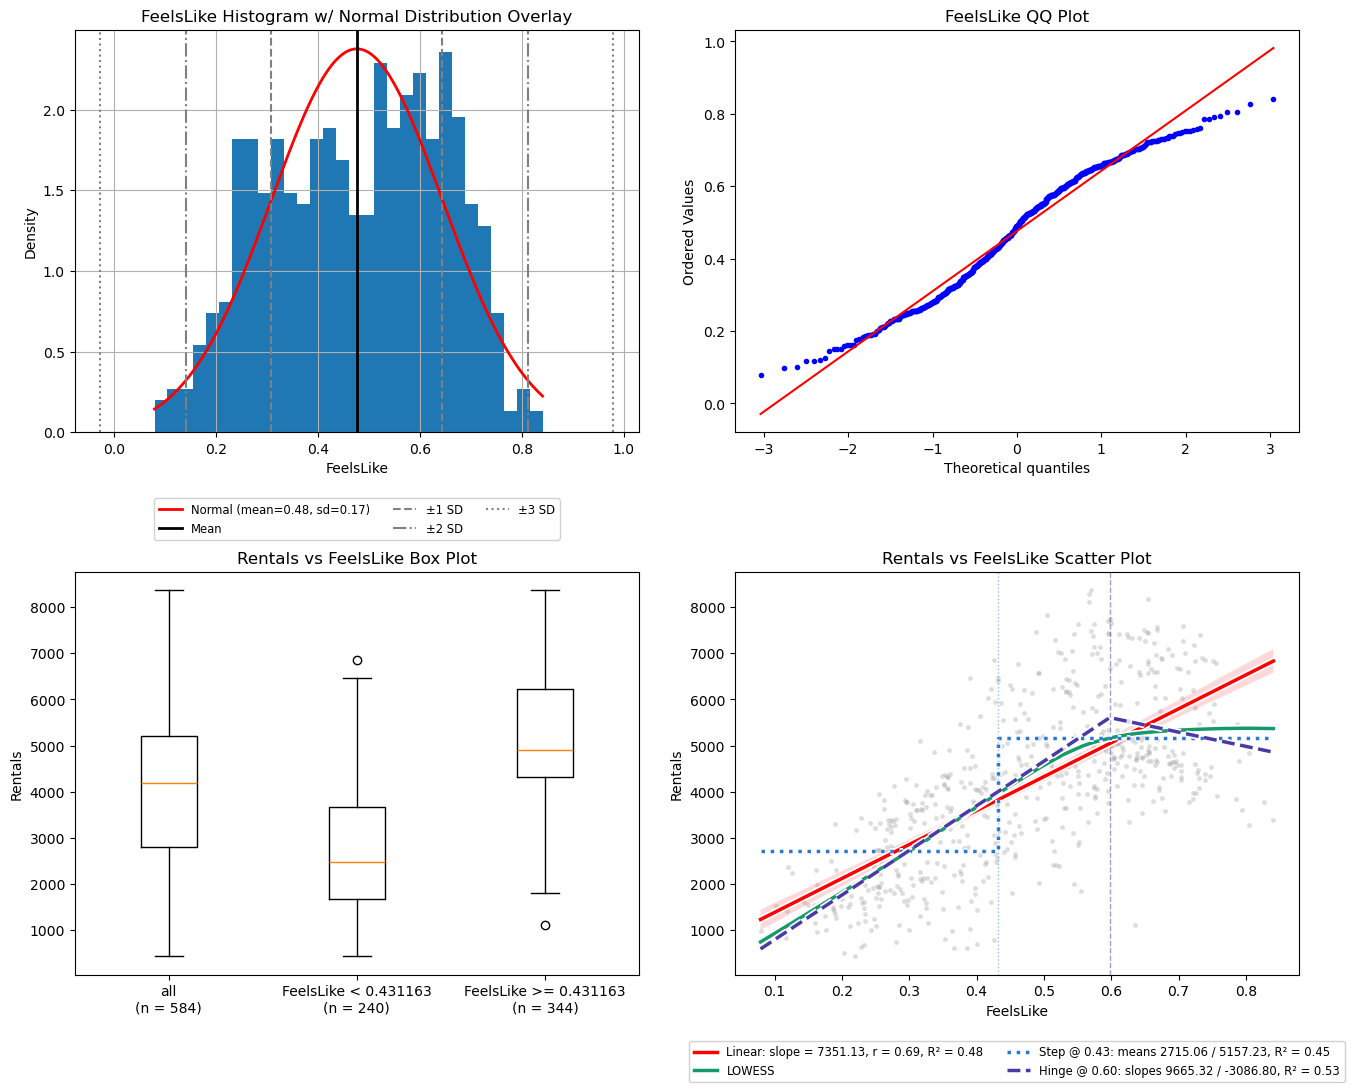

In [10]:
PLOTTING.single_feature_plots(df=train_df, feature='FeelsLike', target=TARGET, threshold="auto");

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **Roughly symmetric (-0.156), mesokurtic (-0.971, close to the platykurtic cutoff of -1).** The histogram is broad with two humps (around 0.25 to 0.3 and around 0.55 to 0.65) and few values above about 0.75.
- **QQ plot:** the low end sits above the line and the high end below it (light tails), the same pattern as Temp.
- **No outliers** on either side.
- **Strongest linear relationship with Rentals:** r = 0.69 (R² 0.48).
- **Rises, then flattens.** LOWESS climbs steeply up to about 0.6 and is flat above it. The hinge at 0.60 changes the slope from 9665.32 to -3086.80 and lifts R² from 0.48 to 0.53. The hinge turns downward at the top end, which LOWESS does not follow.
- The step at 0.43 gives means of 2715.06 / 5157.23 (R² 0.45). In the box plot the 240 rows below 0.431163 have a median Rentals of about 2,450, vs about 4,900 for the 344 rows at or above it.
- **Nearly the same picture as Temp** in every table and plot here (r 0.69 vs 0.685, hinge near 0.6 for both).

#### Special Treatment

- **Same candidates as Temp:** a hinge or spline term near 0.60, or a squared term.
- **No outlier or skew treatment needed.**
- Whether both Temp and FeelsLike are needed is a question for the next notebook.

## Humidity

In [11]:
display(STATISTICS.statistics_df(series=train_df['Humidity'], target=train_df[TARGET]))

,Humidity
count,584.0
missing,0
% missing,0.0
mean,0.623
std,0.148
min,0.0
25%,0.507
50%,0.622
75%,0.73
max,0.972


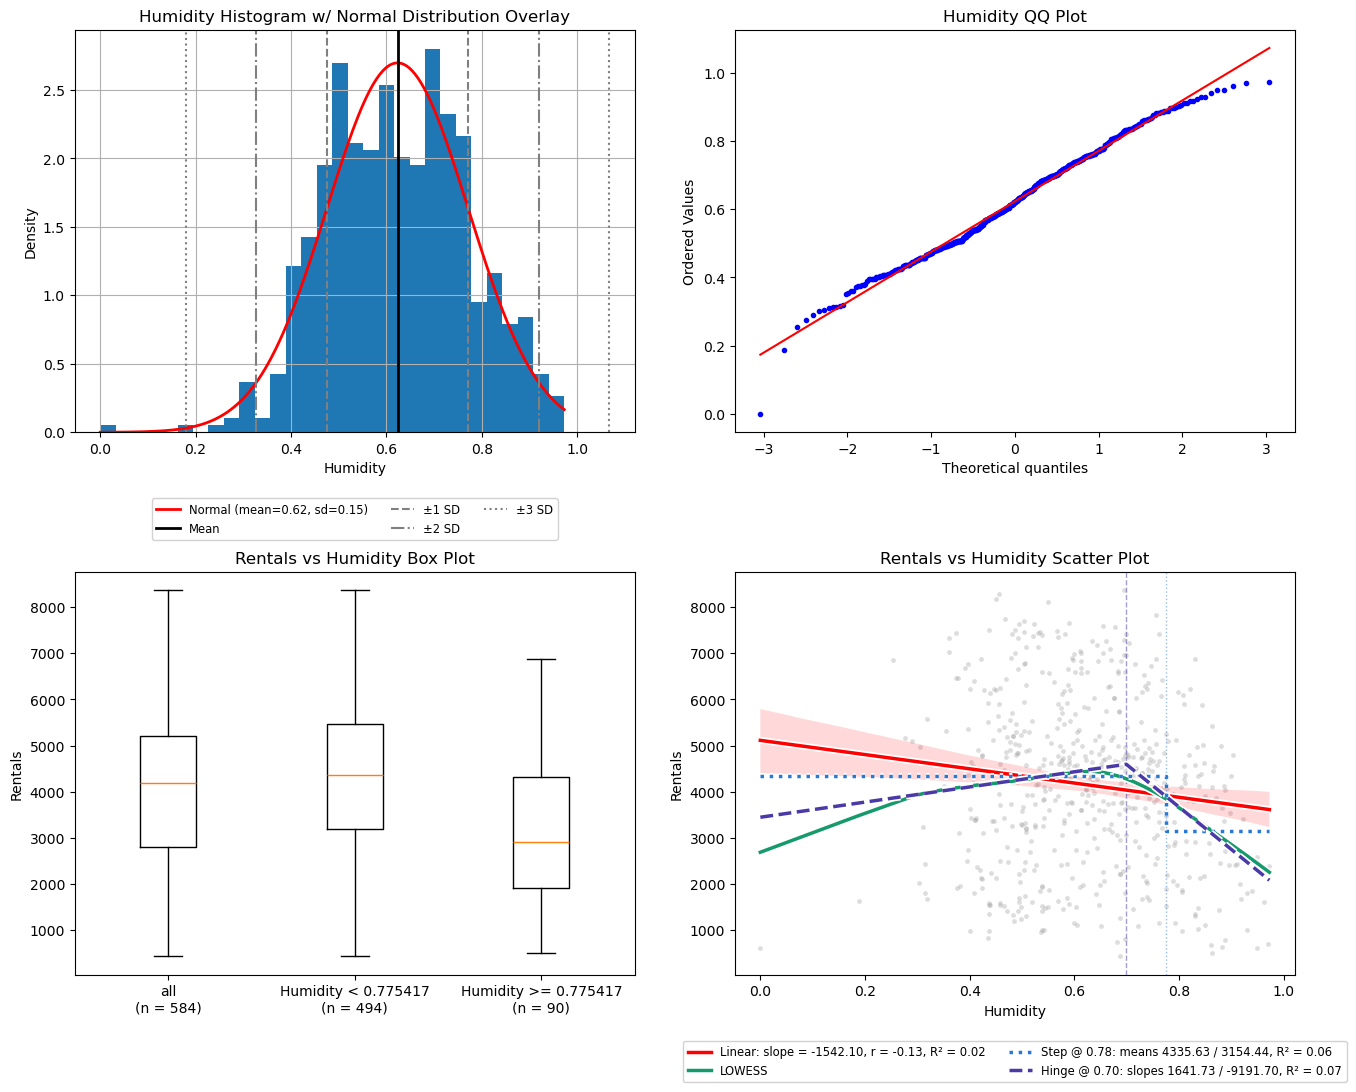

In [12]:
PLOTTING.single_feature_plots(df=train_df, feature='Humidity', target=TARGET, threshold="auto");

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **Roughly symmetric (-0.071), mesokurtic (-0.135).** The histogram follows the normal curve closely. This is the most normal looking of the four continuous attributes.
- **QQ plot:** on the line except for the lowest point, which drops far below it.
- **1 low outlier** below the 0.172 fence, and none above. It is the minimum, a value of exactly 0.0. In the QQ plot the next lowest value is about 0.19. In the scatter plot that row has Rentals of about 600.
- **Weak negative relationship:** r = -0.128 (R² 0.02).
- **Only matters once it is high.** LOWESS rises gently up to about 0.65, then falls steeply. The hinge at 0.70 flips the slope from 1641.73 to -9191.70 (R² 0.07 vs 0.02). The step at 0.78 gives means of 4335.63 / 3154.44 (R² 0.06).
- The box plot shows the same thing: the 90 rows at or above 0.775417 have a median Rentals of about 2,900, vs about 4,350 for the 494 rows below.
- Very few rows sit below about 0.3, so the low end of the LOWESS curve and of the linear fit rests on little data.

#### Special Treatment

- **Check the row with a value of 0.0.** It is one isolated value far from the rest. Candidates: drop the row or replace the value.
- **A hinge term** `max(0, x - t)` with t near 0.70, or an indicator for values at or above about 0.78.
- **No skew treatment needed.**

## Wind

In [13]:
display(STATISTICS.statistics_df(series=train_df['Wind'], target=train_df[TARGET]))

,Wind
count,584.0
missing,0
% missing,0.0
mean,0.194
std,0.076
min,0.022
25%,0.14
50%,0.186
75%,0.234
max,0.507


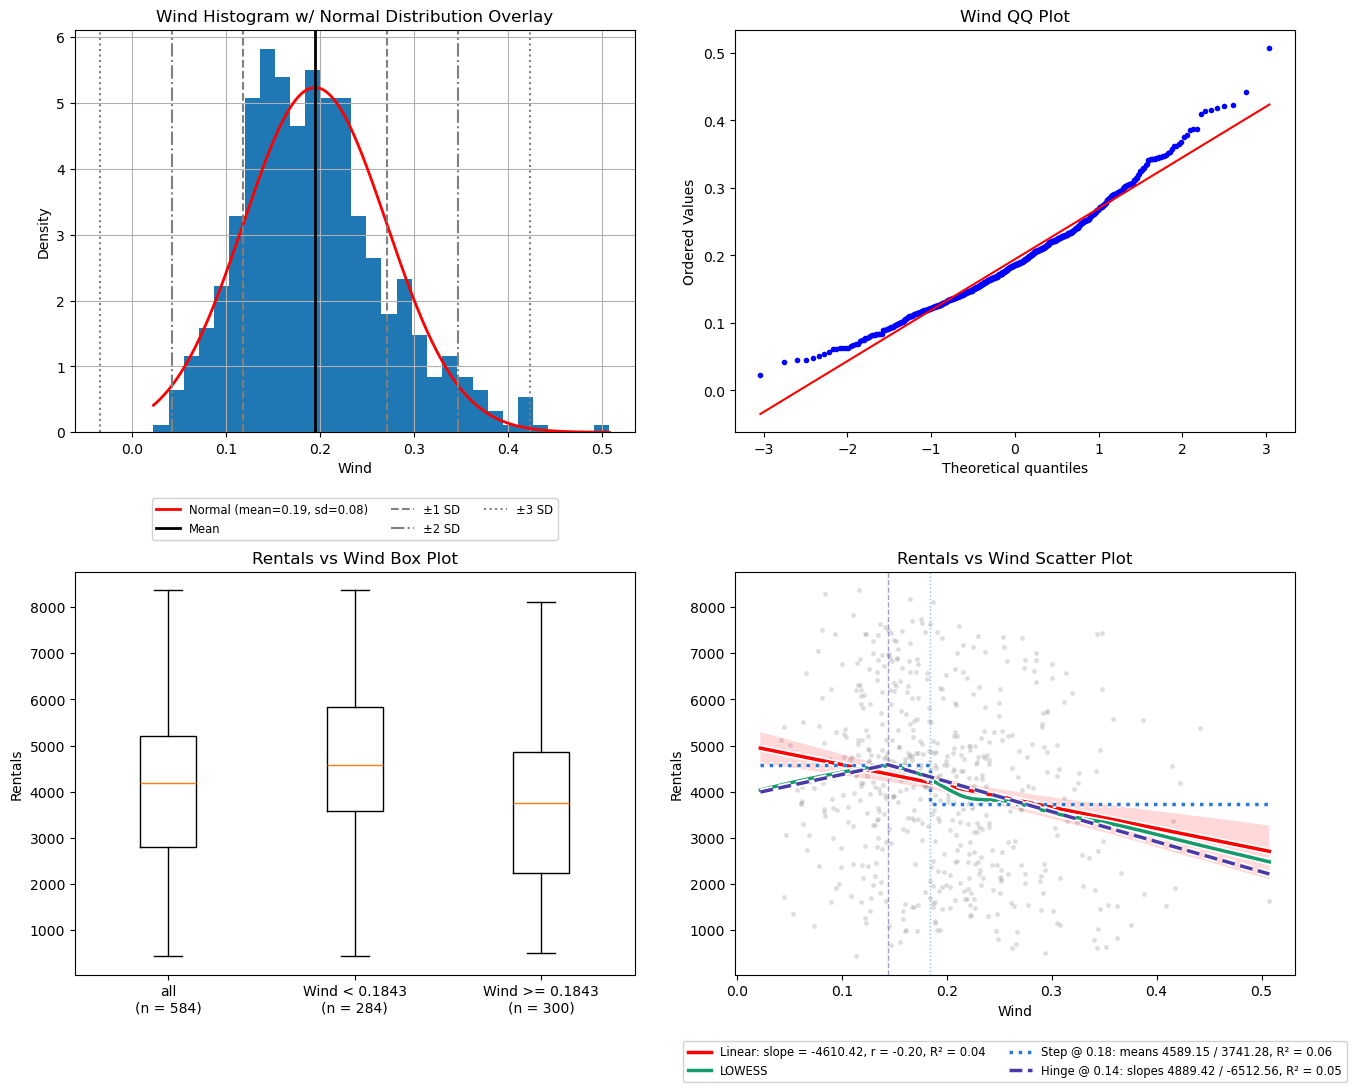

In [14]:
PLOTTING.single_feature_plots(df=train_df, feature='Wind', target=TARGET, threshold="auto");

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **Moderately right skewed (0.668), mesokurtic (0.54).** The histogram peaks around 0.15 to 0.2 with a long right tail up to 0.507. This is the only skewed continuous attribute.
- **QQ plot:** the high end rises above the line (long right tail) and the low end sits above it too (short left tail).
- **12 high outliers** above the 0.376 fence, and none below.
- **Weak negative relationship:** r = -0.196 (R² 0.04).
- **Mostly a gentle decline.** LOWESS rises slightly up to about 0.14, then falls for the rest of the range. The hinge at 0.14 flips the slope from 4889.42 to -6512.56, but only reaches R² 0.05. The step at 0.18 gives means of 4589.15 / 3741.28 (R² 0.06).
- In the box plot the 284 rows below 0.1843 have a median Rentals of about 4,600, vs about 3,750 for the 300 rows at or above it.

#### Special Treatment

- **A transform that pulls in the high tail** (ex log or square root) if the skew needs fixing. All values are positive (min 0.022), so log is possible.
- **Keep the high outliers.** In the scatter plot they sit along the downward trend, not away from it.
- **Low value overall:** leave it in only if it improves the model.

# Statistical Values: Categorical Attributes

## How to Read the Table and Plots (applies to every categorical attribute below)

- **Levels are shown as the codes stored in the file.** A code is a label, not a quantity.
- **Level table:** one row per level, with the number of train rows at that level and the Rentals mean, median, std, min and max within it. `mean - overall mean` is the level's Rentals mean minus the Rentals mean of all train rows.
- **Rows per level (bar chart):** how the train rows are spread across the levels. A level with few rows gives a less reliable mean.
- **Box plot:** Rentals for the rows at each level. The red diamond is the level mean and the dashed line is the overall mean. The further apart the boxes, the more the attribute says about Rentals.
- **Level means R² (box plot title):** the share of the variance in Rentals explained by predicting every row with its level's mean. This is what a one-hot encoded attribute can give a linear regression, so it can be compared with the R² values in the scatter plot legends above.
  - It is scored on the same rows the level means come from, so it is optimistic, more so for an attribute with many levels.

## Season

In [15]:
display(Q2_STATISTICS.category_levels_df(df=train_df, feature='Season', target=TARGET))

,rows,% of rows,Rentals mean,Rentals median,Rentals std,Rentals min,Rentals max,mean - overall mean
Season,,,,,,,,
1,170,29.110,2651.412,2296.0,1412.458,431,7836,-1502.188
2,184,31.507,4992.332,4941.5,1695.977,795,8362,838.732
3,141,24.144,5178.979,4840.0,1294.236,1115,8173,1025.379
4,89,15.240,3664.461,3717.0,983.006,627,5511,-489.139


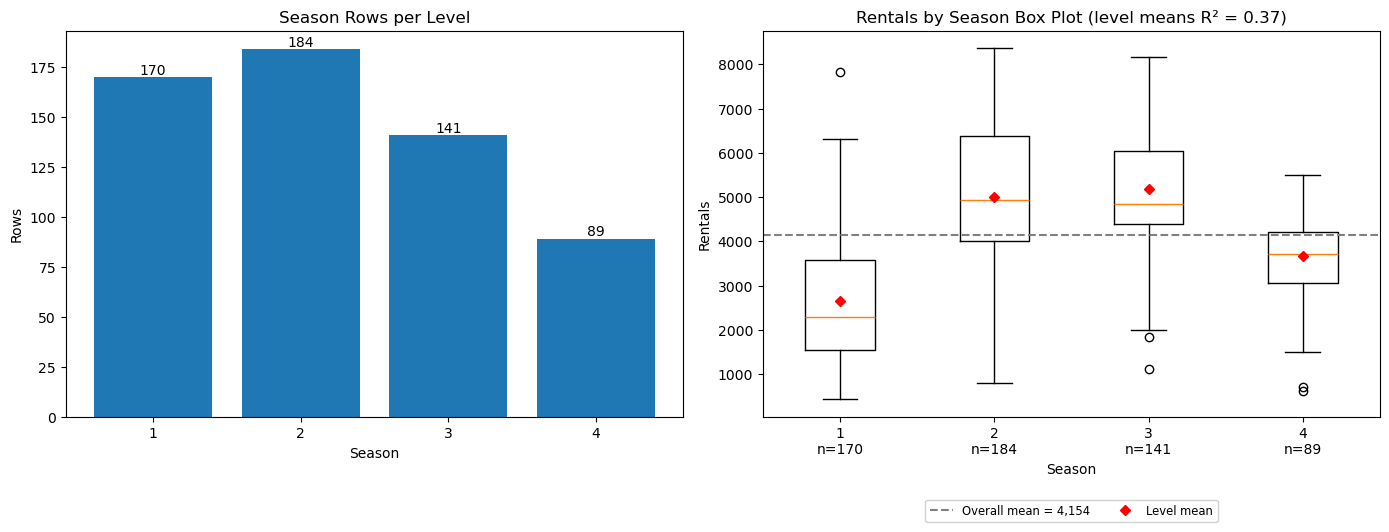

In [16]:
Q2_PLOTTING.categorical_feature_plots(df=train_df, feature='Season', target=TARGET);

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **4 levels with uneven row counts:** 170, 184, 141 and 89. Level 4 has the fewest rows (15.24%).
- **Strong relationship with Rentals:** level means R² = 0.37.
- **The means do not follow the code order.** They run 2,651 / 4,992 / 5,179 / 3,664 for levels 1 to 4: lowest at level 1, highest at levels 2 and 3, and in between at level 4.
- Level 1 sits furthest from the overall mean (-1502.188). Levels 2 and 3 are close to each other (means 4,992 and 5,179).
- The box plot shows a few points outside the whiskers: one high value at level 1 (max 7,836) and low values at levels 3 and 4.

#### Special Treatment

- **One-hot encode.** Read as a number, the code would force Rentals to move in one direction from level 1 to level 4, which the means do not do.

## Year

In [17]:
display(Q2_STATISTICS.category_levels_df(df=train_df, feature='Year', target=TARGET))

,rows,% of rows,Rentals mean,Rentals median,Rentals std,Rentals min,Rentals max,mean - overall mean
Year,,,,,,,,
0,365,62.5,3405.762,3740.0,1378.754,431,6043,-747.838
1,219,37.5,5399.995,5823.0,1699.125,1027,8362,1246.396


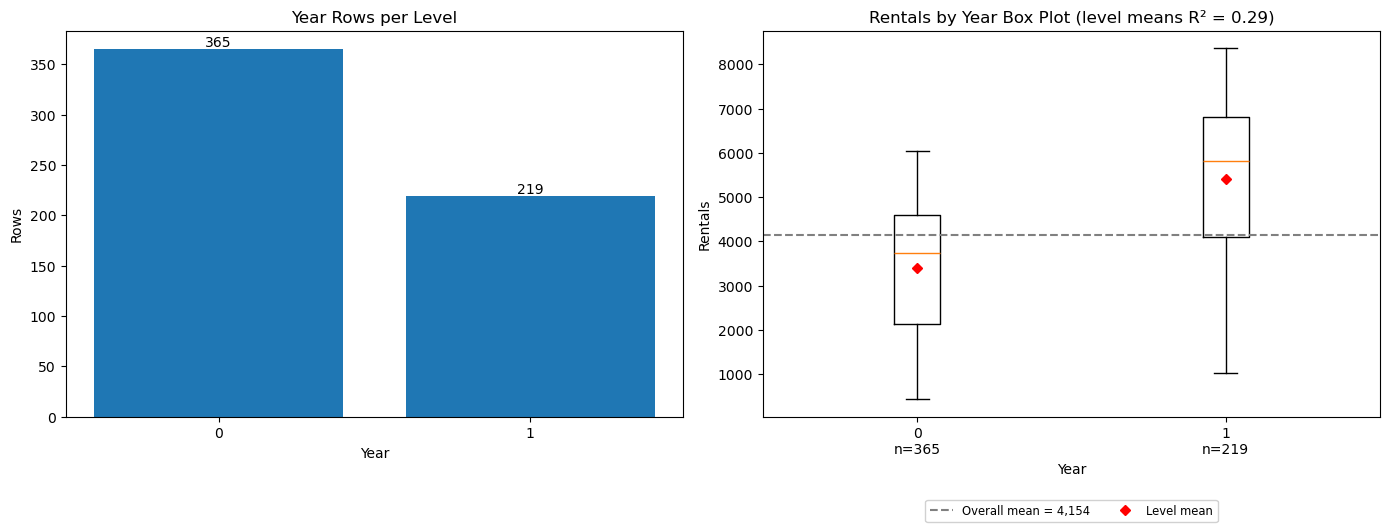

In [18]:
Q2_PLOTTING.categorical_feature_plots(df=train_df, feature='Year', target=TARGET);

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **2 levels with uneven row counts:** 365 rows at level 0 (62.5%) and 219 at level 1 (37.5%). Train ends on 2012-08-06, so level 1 only covers part of a year.
- **Clear shift between the levels:** level means R² = 0.29. The mean is 3,406 at level 0 and 5,400 at level 1, and the median is 3,740 vs 5,823.
- **Level 1 also reaches higher values:** max 8,362 vs 6,043 at level 0.
- The spread is wider at level 1 (std 1,699 vs 1,379).

#### Special Treatment

- **None needed for encoding.** It is already a 0 / 1 indicator.
- **Every test row is at level 1** (the test dates are 2012-08-07 to 2012-12-31), so this attribute is what tells a model which of the two Rentals levels applies.

## Month

In [19]:
display(Q2_STATISTICS.category_levels_df(df=train_df, feature='Month', target=TARGET))

,rows,% of rows,Rentals mean,Rentals median,Rentals std,Rentals min,Rentals max,mean - overall mean
Month,,,,,,,,
1,62,10.616,2176.339,1939.0,1161.674,431,4521,-1977.261
2,57,9.760,2655.298,2402.0,1145.313,1005,5062,-1498.301
3,62,10.616,3692.258,3216.5,1899.302,605,8362,-461.341
4,60,10.274,4484.900,4293.5,1776.161,795,7460,331.301
5,62,10.616,5349.774,4890.5,1298.712,2633,8294,1196.175
6,60,10.274,5772.367,5308.5,1240.400,3767,8120,1618.767
7,62,10.616,5563.677,5446.5,1273.752,3285,8173,1410.078
8,37,6.336,4811.027,4694.0,1216.343,1115,7580,657.428
9,30,5.137,4247.267,4584.5,965.377,1842,5423,93.667


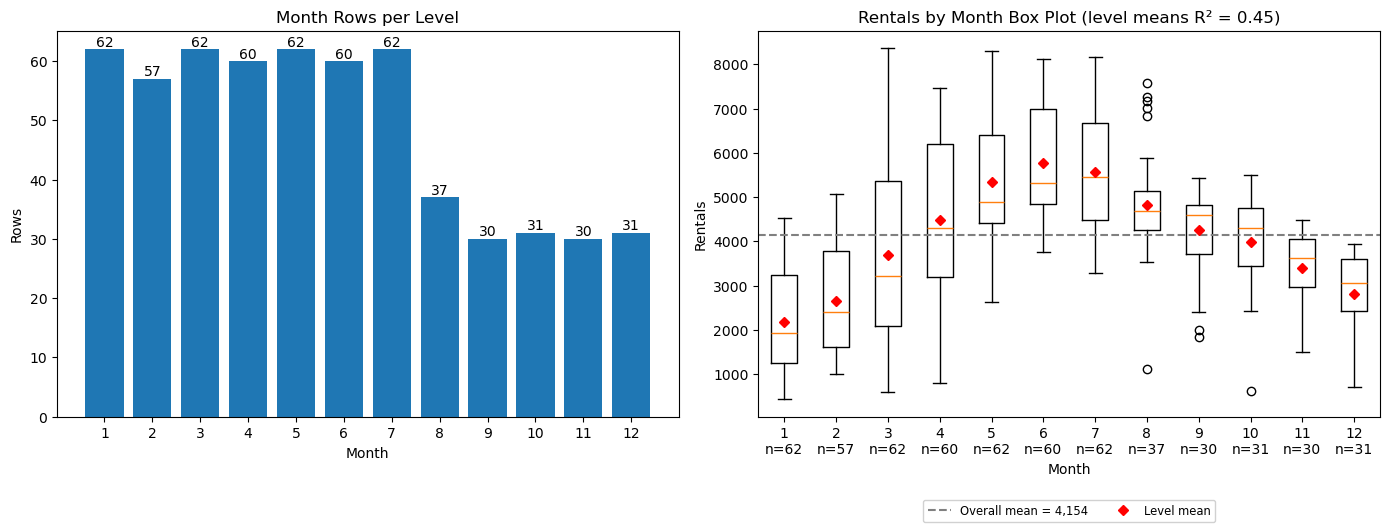

In [20]:
Q2_PLOTTING.categorical_feature_plots(df=train_df, feature='Month', target=TARGET);

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **12 levels with uneven row counts:** months 1 to 7 have 57 to 62 rows each, month 8 has 37, and months 9 to 12 have 30 or 31.
- **Strongest categorical relationship with Rentals:** level means R² = 0.45.
- **Rises, then falls.** The mean climbs from 2,176 at month 1 to 5,772 at month 6, then drops back to 2,817 at month 12.
- **The spread differs by month.** Months 3 and 4 are the widest (std 1,899 and 1,776). Months 9 to 12 are narrower (std 788 to 1,103).
- **Months 9 to 12 only have rows from the first year,** since train ends on 2012-08-06. Months 1 to 7 have rows from both years. The Year section shows the second year runs higher (mean 5,400 vs 3,406), so the means of months 9 to 12 are not on the same footing as those of months 1 to 7.

#### Special Treatment

- **One-hot encode.** A straight line through the codes 1 to 12 cannot follow means that rise and then fall.
- **Or a cyclical encoding** (sine and cosine of the month), which uses 2 columns instead of 12 and keeps month 12 next to month 1.
- **Keep the uneven year coverage in mind** when reading the month effects in the next notebook.

## IsHoliday

In [21]:
display(Q2_STATISTICS.category_levels_df(df=train_df, feature='IsHoliday', target=TARGET))

,rows,% of rows,Rentals mean,Rentals median,Rentals std,Rentals min,Rentals max,mean - overall mean
IsHoliday,,,,,,,,
0,568,97.26,4169.87,4262.0,1779.748,431,8362,16.270
1,16,2.74,3576.00,3240.0,2068.932,1000,7403,-577.599


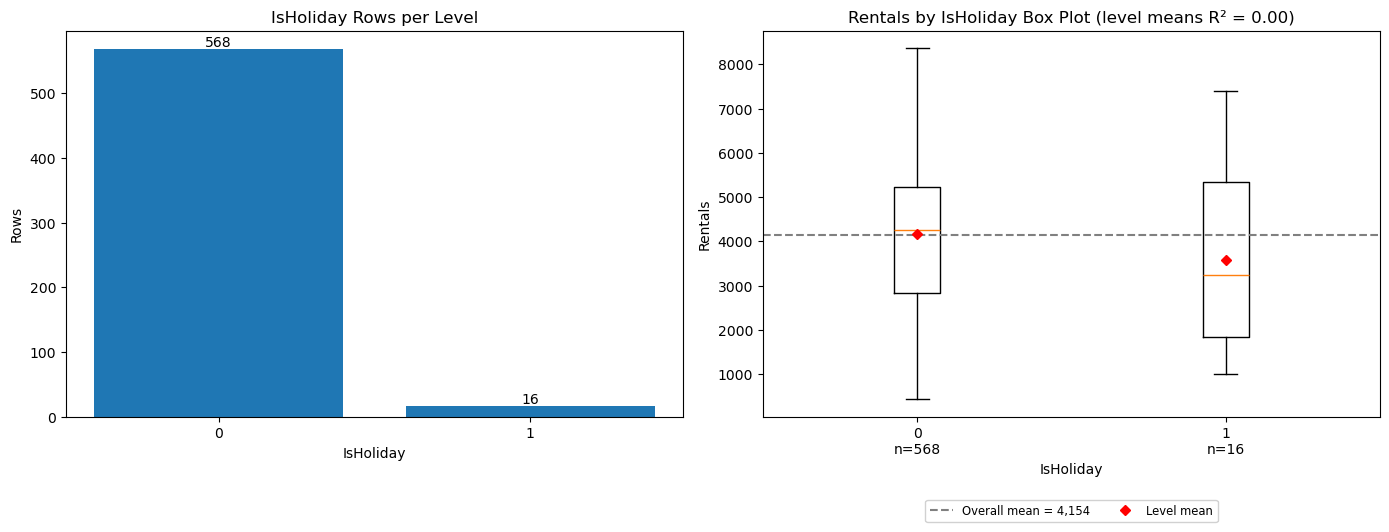

In [22]:
Q2_PLOTTING.categorical_feature_plots(df=train_df, feature='IsHoliday', target=TARGET);

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **Very uneven:** 568 rows at level 0 (97.26%) and only 16 at level 1 (2.74%).
- **No measurable relationship with Rentals:** level means R² = 0.00.
- The mean is lower at level 1 (3,576 vs 4,170), but that rests on 16 rows that span almost the full range (1,000 to 7,403, std 2,069). In the box plot the two boxes overlap heavily.

#### Special Treatment

- **None needed for encoding.** It is already a 0 / 1 indicator.
- **Low value overall:** with 16 rows at level 1 its effect cannot be estimated reliably. A candidate to drop, or to leave in only if it improves the model.

## Weekday

In [23]:
display(Q2_STATISTICS.category_levels_df(df=train_df, feature='Weekday', target=TARGET))

,rows,% of rows,Rentals mean,Rentals median,Rentals std,Rentals min,Rentals max,mean - overall mean
Weekday,,,,,,,,
0,84,14.384,3997.417,4032.0,1795.027,605,7641,-156.183
1,84,14.384,4051.738,4092.0,1627.219,1000,7105,-101.861
2,83,14.212,4211.892,4451.0,1676.713,683,7592,58.292
3,83,14.212,4085.711,4186.0,1843.334,506,8173,-67.888
4,83,14.212,4271.048,4189.0,1794.236,431,7494,117.449
5,83,14.212,4290.012,4151.0,1747.653,1167,8362,136.413
6,84,14.384,4170.286,4257.0,2049.309,627,8294,16.686


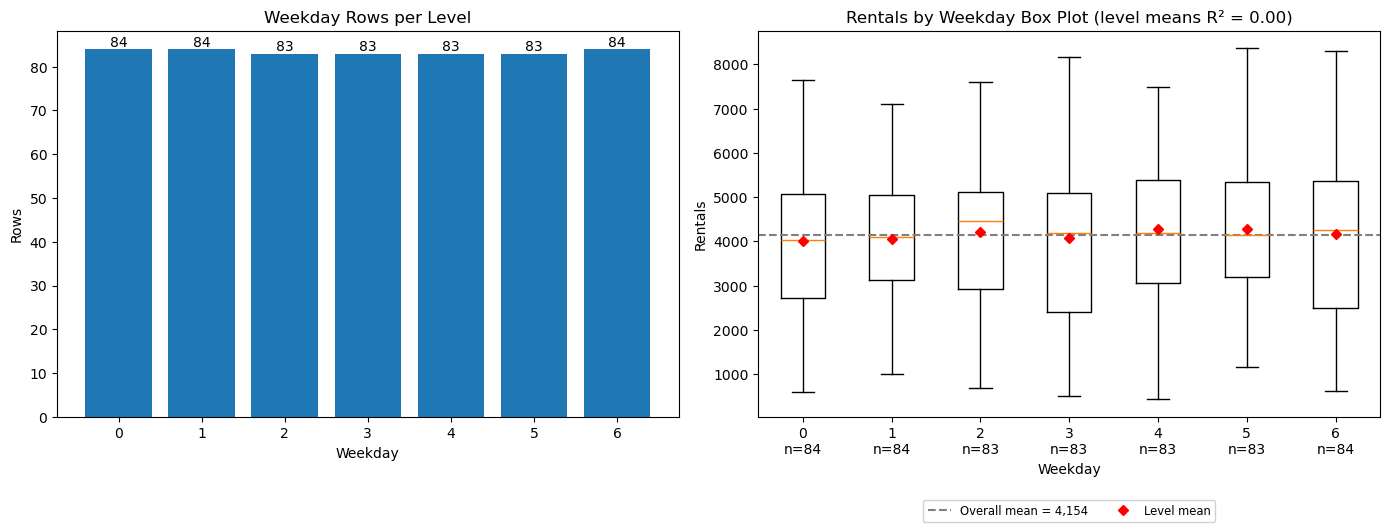

In [24]:
Q2_PLOTTING.categorical_feature_plots(df=train_df, feature='Weekday', target=TARGET);

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **7 evenly filled levels:** 83 or 84 rows each.
- **No relationship with Rentals:** level means R² = 0.00.
- **Flat across the levels.** The means run from 3,997 (level 0) to 4,290 (level 5), and the largest gap from the overall mean is -156.183. The boxes in the box plot overlap almost completely.

#### Special Treatment

- **One-hot encode if it is kept,** since the codes 0 to 6 are labels.
- **Low value overall:** a candidate to drop.

## IsWorkday

In [25]:
display(Q2_STATISTICS.category_levels_df(df=train_df, feature='IsWorkday', target=TARGET))

,rows,% of rows,Rentals mean,Rentals median,Rentals std,Rentals min,Rentals max,mean - overall mean
IsWorkday,,,,,,,,
0,184,31.507,4039.690,4108.0,1935.064,605,8294,-113.909
1,400,68.493,4205.998,4268.0,1717.480,431,8362,52.398


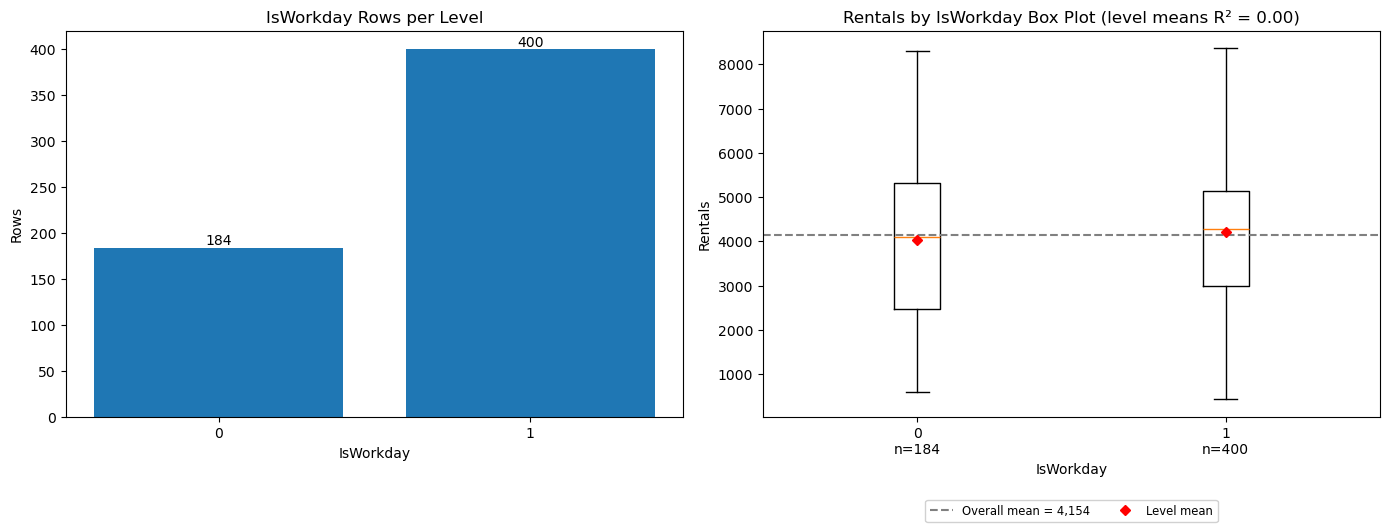

In [26]:
Q2_PLOTTING.categorical_feature_plots(df=train_df, feature='IsWorkday', target=TARGET);

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **2 levels:** 184 rows at level 0 (31.507%) and 400 at level 1 (68.493%).
- **No relationship with Rentals:** level means R² = 0.00. The means are 4,040 and 4,206, and the medians 4,108 and 4,268.
- The spread is slightly wider at level 0 (std 1,935 vs 1,717).

#### Special Treatment

- **None needed for encoding.** It is already a 0 / 1 indicator.
- **Low value overall:** a candidate to drop, or to leave in only if it improves the model.

## Weather

In [27]:
display(Q2_STATISTICS.category_levels_df(df=train_df, feature='Weather', target=TARGET))

,rows,% of rows,Rentals mean,Rentals median,Rentals std,Rentals min,Rentals max,mean - overall mean
Weather,,,,,,,,
1,377,64.555,4509.897,4586.0,1742.077,431,8294,356.297
2,189,32.363,3665.101,3747.0,1656.598,605,8362,-488.499
3,18,3.082,1820.389,1829.5,1020.114,506,4459,-2333.210


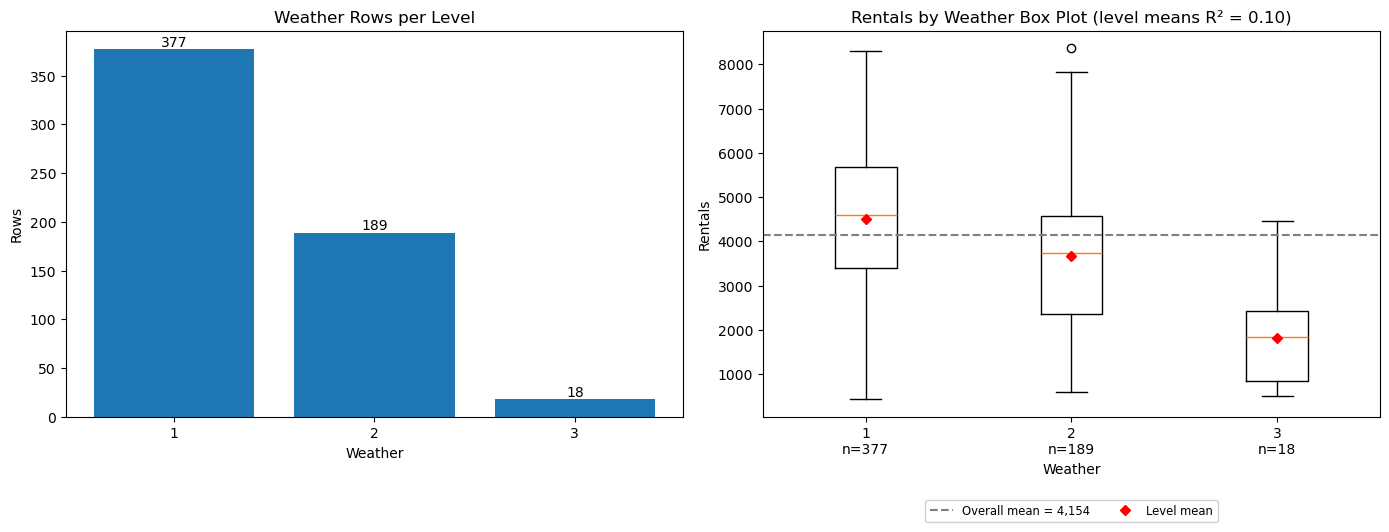

In [28]:
Q2_PLOTTING.categorical_feature_plots(df=train_df, feature='Weather', target=TARGET);

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **3 levels with very uneven row counts:** 377 rows at level 1 (64.555%), 189 at level 2 (32.363%) and only 18 at level 3 (3.082%).
- **Weak relationship with Rentals:** level means R² = 0.10.
- **Rentals fall as the code rises.** The means are 4,510 / 3,665 / 1,820 for levels 1 to 3. The drop from level 2 to level 3 is larger than the drop from level 1 to level 2.
- **Level 3 never reaches the high values:** its max is 4,459, vs 8,294 and 8,362 at levels 1 and 2.

#### Special Treatment

- **One-hot encode.** The means are in code order, but the steps between levels are not equal, which a single numeric column cannot follow.
- **Level 3 is rare.** Its effect is the largest (mean - overall mean of -2333.210) but rests on 18 rows.

# Columns Without a Section

In [29]:
print(f"ID: {train_df['ID'].nunique()} distinct values in {len(train_df)} train rows, from {train_df['ID'].min()} to {train_df['ID'].max()}.")
print(f"Date: {train_df['Date'].nunique()} distinct values in {len(train_df)} train rows.")
print(f"Casual + Registered equals {TARGET} in every train row: {(train_df['Casual'] + train_df['Registered'] == train_df[TARGET]).all()}")

ID: 584 distinct values in 584 train rows, from 1 to 584.
Date: 584 distinct values in 584 train rows.
Casual + Registered equals Rentals in every train row: True


These four columns do not get a section of their own:

- **`ID`:** a row counter with 584 distinct values in 584 train rows (1 to 584). It labels the row and is not a measurement.
- **`Date`:** one distinct value per train row, so on its own it cannot be summarized like the attributes above. `Year`, `Month` and `Weekday` already describe the date.
- **`Casual` and `Registered`:** they add up to `Rentals` in every train row. They are the two parts of the target, so using them as attributes would give the answer away.

#### Special Treatment

- **Do not use `Casual` or `Registered` as attributes.**
- **Do not use `ID` or `Date` as they are.**